In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from rpy2.robjects import r
from rpy2.robjects import pandas2ri
from rpy2.robjects.packages import importr
from rpy2.robjects.conversion import localconverter
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from sklearn.linear_model import LinearRegression
import matplotlib.ticker as mticker

In [2]:
# Load cohort classification results
df_cohort_sammed = pd.read_csv('../../local/output/cohort_cls_sammed_results.csv')
df_cohort_sammed.set_index('split', inplace=True)
df_cohort_sammed['model'] = 'SAM-Med3D'

df_cohort_brainiac = pd.read_csv('../../local/output/cohort_cls_brainiac_results.csv')
df_cohort_brainiac.set_index('split', inplace=True)
df_cohort_brainiac['model'] = 'BrainIAC'


In [3]:
df_cohort_sammed.head()

,experiment,balanced_accuracy,f1_score,auc,model
split,,,,,
0,ADNI_AIBL,0.5,0.778267,0.654330,SAM-Med3D
1,ADNI_AIBL,0.5,0.778267,0.680757,SAM-Med3D
2,ADNI_AIBL,0.5,0.778267,0.623041,SAM-Med3D
3,ADNI_AIBL,0.5,0.778267,0.663839,SAM-Med3D
4,ADNI_AIBL,0.5,0.778267,0.725653,SAM-Med3D


In [4]:
# Load disease classification results
df_disease_sammed = pd.read_csv('../../local/output/disease_cls_sammed_results.csv')
df_disease_sammed.set_index('split', inplace=True)
df_disease_sammed['model'] = 'SAM-Med3D'
df_disease_sammed['experiment'] = df_disease_sammed['train'] + '_' + df_disease_sammed['test']
df_disease_brainiac = pd.read_csv('../../local/output/disease_cls_brainiac_results.csv')
df_disease_brainiac.set_index('split', inplace=True)
df_disease_brainiac['model'] = 'BrainIAC'

In [5]:
df_disease_sammed.head()

,train,test,balanced_accuracy,f1_score,auc,wasserstein_dist,model,experiment
split,,,,,,,,
0,ADNI,ADNI,0.666054,0.579330,0.742225,0.004943,SAM-Med3D,ADNI_ADNI
0,ADNI,AIBL,0.681213,0.450450,0.750906,0.016004,SAM-Med3D,ADNI_AIBL
0,ADNI,OASIS3,0.595545,0.217391,0.712502,0.014604,SAM-Med3D,ADNI_OASIS3
0,ADNI,BrainLAT,0.557873,0.299213,0.736369,0.031529,SAM-Med3D,ADNI_BrainLAT
0,ADNI,NigerianBrain,0.590177,0.344828,0.702093,0.102489,SAM-Med3D,ADNI_NigerianBrain


In [6]:
df_cohort_all = pd.concat([df_cohort_sammed, df_cohort_brainiac], axis=0)
df_disease_all = pd.concat([df_disease_sammed, df_disease_brainiac], axis=0)

# remove internal validation results
df_disease_all = df_disease_all[
    df_disease_all["train"] != df_disease_all["test"]
]

# AUC

In [7]:
metric_col = 'auc'

In [8]:
cohort_summary = (
    df_cohort_all
    .groupby(["experiment", "model"])[metric_col]
    .agg(cohort_mean="mean", cohort_std="std")
    .reset_index()
)
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)


In [9]:
cohort_summary

,experiment,model,cohort_mean,cohort_std,cohort_pair
0,ADNI_AIBL,BrainIAC,0.664838,0.030693,"(ADNI, AIBL)"
1,ADNI_AIBL,SAM-Med3D,0.655399,0.035068,"(ADNI, AIBL)"
2,ADNI_BrainLAT,BrainIAC,0.903124,0.019795,"(ADNI, BrainLAT)"
3,ADNI_BrainLAT,SAM-Med3D,0.867848,0.022628,"(ADNI, BrainLAT)"
4,ADNI_NigerianBrain,BrainIAC,0.972102,0.021196,"(ADNI, NigerianBrain)"
5,ADNI_NigerianBrain,SAM-Med3D,0.933288,0.033872,"(ADNI, NigerianBrain)"
6,ADNI_OASIS3,BrainIAC,0.610215,0.025550,"(ADNI, OASIS3)"
7,ADNI_OASIS3,SAM-Med3D,0.533785,0.025408,"(ADNI, OASIS3)"
8,AIBL_BrainLAT,BrainIAC,0.806245,0.024623,"(AIBL, BrainLAT)"
9,AIBL_BrainLAT,SAM-Med3D,0.814857,0.022432,"(AIBL, BrainLAT)"


In [10]:
disease_summary = (
    df_disease_all
    .groupby(["train", "test", "model"])[metric_col]
    .agg(disease_mean="mean", disease_std="std")
    .reset_index()
)

disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)
disease_summary

,train,test,model,disease_mean,disease_std,cohort_pair
0,ADNI,AIBL,BrainIAC,0.790019,0.018763,"(ADNI, AIBL)"
1,ADNI,AIBL,SAM-Med3D,0.731302,0.010899,"(ADNI, AIBL)"
2,ADNI,BrainLAT,BrainIAC,0.632141,0.040236,"(ADNI, BrainLAT)"
3,ADNI,BrainLAT,SAM-Med3D,0.732549,0.007471,"(ADNI, BrainLAT)"
4,ADNI,NigerianBrain,BrainIAC,0.573752,0.109940,"(ADNI, NigerianBrain)"
5,ADNI,NigerianBrain,SAM-Med3D,0.692110,0.020110,"(ADNI, NigerianBrain)"
6,ADNI,OASIS3,BrainIAC,0.651437,0.012706,"(ADNI, OASIS3)"
7,ADNI,OASIS3,SAM-Med3D,0.702459,0.006779,"(ADNI, OASIS3)"
8,AIBL,ADNI,BrainIAC,0.728207,0.005967,"(ADNI, AIBL)"
9,AIBL,ADNI,SAM-Med3D,0.573753,0.034859,"(ADNI, AIBL)"


In [11]:
def add_cohort_pair(df):
    df = df.copy()
    df["cohort_pair"] = (
        df["experiment"]
        .str.split("_")
        .apply(lambda x: "_".join(sorted(x)))
    )
    return df

In [12]:
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)
disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)

In [13]:
combined_df = (
    disease_summary
    .merge(
        cohort_summary[["cohort_pair", "model", "cohort_mean", "cohort_std"]],
        on=["cohort_pair", "model"],
        how="inner"
    )
)

In [14]:
combined_df["cohort_pair"] = combined_df["cohort_pair"].apply(lambda x: "_".join(x))

In [15]:
combined_df

,train,test,model,disease_mean,disease_std,cohort_pair,cohort_mean,cohort_std
0,ADNI,AIBL,BrainIAC,0.790019,0.018763,ADNI_AIBL,0.664838,0.030693
1,ADNI,AIBL,SAM-Med3D,0.731302,0.010899,ADNI_AIBL,0.655399,0.035068
2,ADNI,BrainLAT,BrainIAC,0.632141,0.040236,ADNI_BrainLAT,0.903124,0.019795
3,ADNI,BrainLAT,SAM-Med3D,0.732549,0.007471,ADNI_BrainLAT,0.867848,0.022628
4,ADNI,NigerianBrain,BrainIAC,0.573752,0.109940,ADNI_NigerianBrain,0.972102,0.021196
5,ADNI,NigerianBrain,SAM-Med3D,0.692110,0.020110,ADNI_NigerianBrain,0.933288,0.033872
6,ADNI,OASIS3,BrainIAC,0.651437,0.012706,ADNI_OASIS3,0.610215,0.025550
7,ADNI,OASIS3,SAM-Med3D,0.702459,0.006779,ADNI_OASIS3,0.533785,0.025408
8,AIBL,ADNI,BrainIAC,0.728207,0.005967,ADNI_AIBL,0.664838,0.030693
9,AIBL,ADNI,SAM-Med3D,0.573753,0.034859,ADNI_AIBL,0.655399,0.035068


In [16]:
combined_df['experiment'] = combined_df['train'] + '_' + combined_df['test'] + '-' + combined_df['model']

In [17]:
rho, p_value = stats.spearmanr(combined_df['cohort_mean'], combined_df['disease_mean'])
rho, p_value

(-0.07511740400600435, 0.6450346073626689)

In [18]:
stats_r = importr('stats')
# convert to R dataframe
with localconverter(pandas2ri.converter):
    r_df = pandas2ri.py2rpy(combined_df)

In [19]:
# ----- ANOVA: disease_mean ~ cohort_mean -----
anova1 = stats_r.aov(r('disease_mean ~ cohort_mean'), data=r_df)
print(r['summary'](anova1))

R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  


            Df Sum Sq  Mean Sq F value Pr(>F)
cohort_mean  1 0.0001 0.000052   0.006  0.938
Residuals   38 0.3189 0.008392               



In [20]:
# ----- ANOVA: disease_mean ~ cohort_mean + model -----
anova2 = stats_r.aov(r('disease_mean ~ cohort_mean + model'), data=r_df)
print(r['summary'](anova2))

            Df  Sum Sq Mean Sq F value Pr(>F)  
cohort_mean  1 0.00005 0.00005   0.007 0.9350  
model        1 0.03285 0.03285   4.249 0.0463 *
Residuals   37 0.28605 0.00773                 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



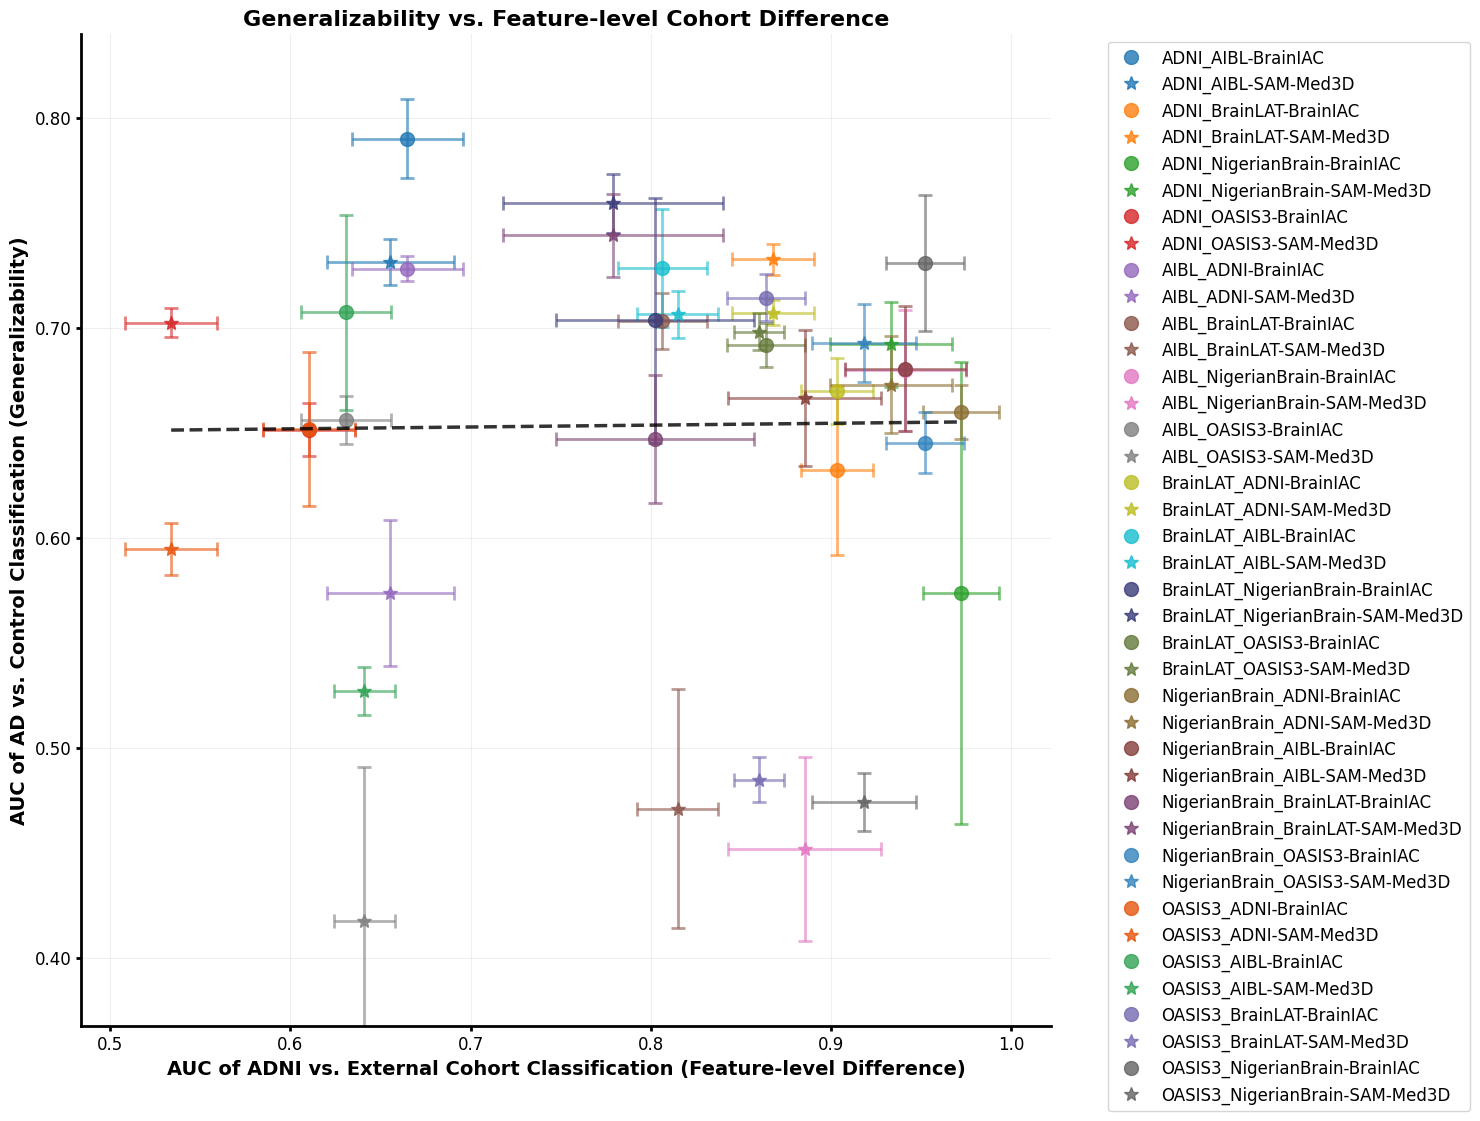

Spearman's ρ (rho): -0.075, p-value: 0.6450
Pearson's r: 0.013, p-value: 0.9376


In [21]:
# Example exp_names (for context)

exp_names = combined_df['experiment'].tolist()

# Define colors for each dataset prefix
dataset_names = sorted(set([name.split('-')[0] for name in exp_names]))
color_map = dict(zip(dataset_names,  [
    "#1f77b4",  # Blue
    "#ff7f0e",  # Orange
    "#2ca02c",  # Green
    "#d62728",  # Red
    "#9467bd",  # Purple
    "#8c564b",  # Brown
    "#e377c2",  # Pink
    "#7f7f7f",  # Gray
    "#bcbd22",  # Olive
    "#17becf",  # Teal
    "#393b79",  # Dark Blue
    "#637939",  # Dark Green
    "#8c6d31",  # Dark Brown
    "#843c39",  # Dark Red
    "#7b4173",  # Violet
    "#3182bd",  # Light Blue
    "#e6550d",  # Deep Orange
    "#31a354",  # Bright Green
    "#756bb1",  # Medium Purple
    "#636363"   # Dark Gray
]))

# Assign markers based on suffix
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*'}

mean_cohort_acc = combined_df['cohort_mean'].values
mean_adcn_acc = combined_df['disease_mean'].values
std_cohort_acc = combined_df['cohort_std'].values
std_adcn_acc = combined_df['disease_std'].values
# Prepare plot data with color and marker
plot_data = []
for i, name in enumerate(exp_names):
    dataset_prefix = name.split('-')[0]
    experiment_suffix = '-'.join(name.split('-')[1:])
    color = color_map[dataset_prefix]
    marker = marker_map.get(experiment_suffix, 'o')  # default to circle if unknown
    plot_data.append((name, mean_cohort_acc[i], mean_adcn_acc[i], 
                     std_cohort_acc[i], std_adcn_acc[i], color, marker))

# Sort alphabetically for legend
plot_data.sort(key=lambda x: x[0])

# Create figure
plt.figure(figsize=(15, 12))

# Plot error bars
for name, x, y, xerr, yerr, color, marker in plot_data:
    plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
                 capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# Plot scatter points
for name, x, y, xerr, yerr, color, marker in plot_data:
    plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
             linestyle='none', label=name)

# Linear regression trend line
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression()
lr_model.fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
plt.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
         label='_nolegend_')  # prevents trendline from appearing in legend

# Labels and title
plt.xlabel('AUC of ADNI vs. External Cohort Classification (Feature-level Difference)', fontsize=14, fontweight='bold')
plt.ylabel('AUC of AD vs. Control Classification (Generalizability)', fontsize=14, fontweight='bold')
plt.title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes formatting
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.tick_params(width=2, labelsize=12)

ax = plt.gca()
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
plt.grid(True, alpha=0.2, linestyle='-')

# Axis limits with padding
plt.xlim(min(mean_cohort_acc) - 0.05, max(mean_cohort_acc) + 0.05)
plt.ylim(min(mean_adcn_acc) - 0.05, max(mean_adcn_acc) + 0.05)

# Legend below plot, alphabetical order
handles, labels = ax.get_legend_handles_labels()
sorted_handles_labels = sorted(zip(labels, handles), key=lambda x: x[0])
labels_sorted, handles_sorted = zip(*sorted_handles_labels)
plt.legend(handles_sorted, labels_sorted, bbox_to_anchor=(1.05, 1), loc='upper left',
           fontsize=12)

plt.tight_layout()
plt.show()

# Spearman correlation
rho, p_value = stats.spearmanr(mean_cohort_acc, mean_adcn_acc)
print(f"Spearman's ρ (rho): {rho:.3f}, p-value: {p_value:.4f}")

# Pearson correlation
pearson_r, pearson_p = stats.pearsonr(mean_cohort_acc, mean_adcn_acc)
print(f"Pearson's r: {pearson_r:.3f}, p-value: {pearson_p:.4f}")


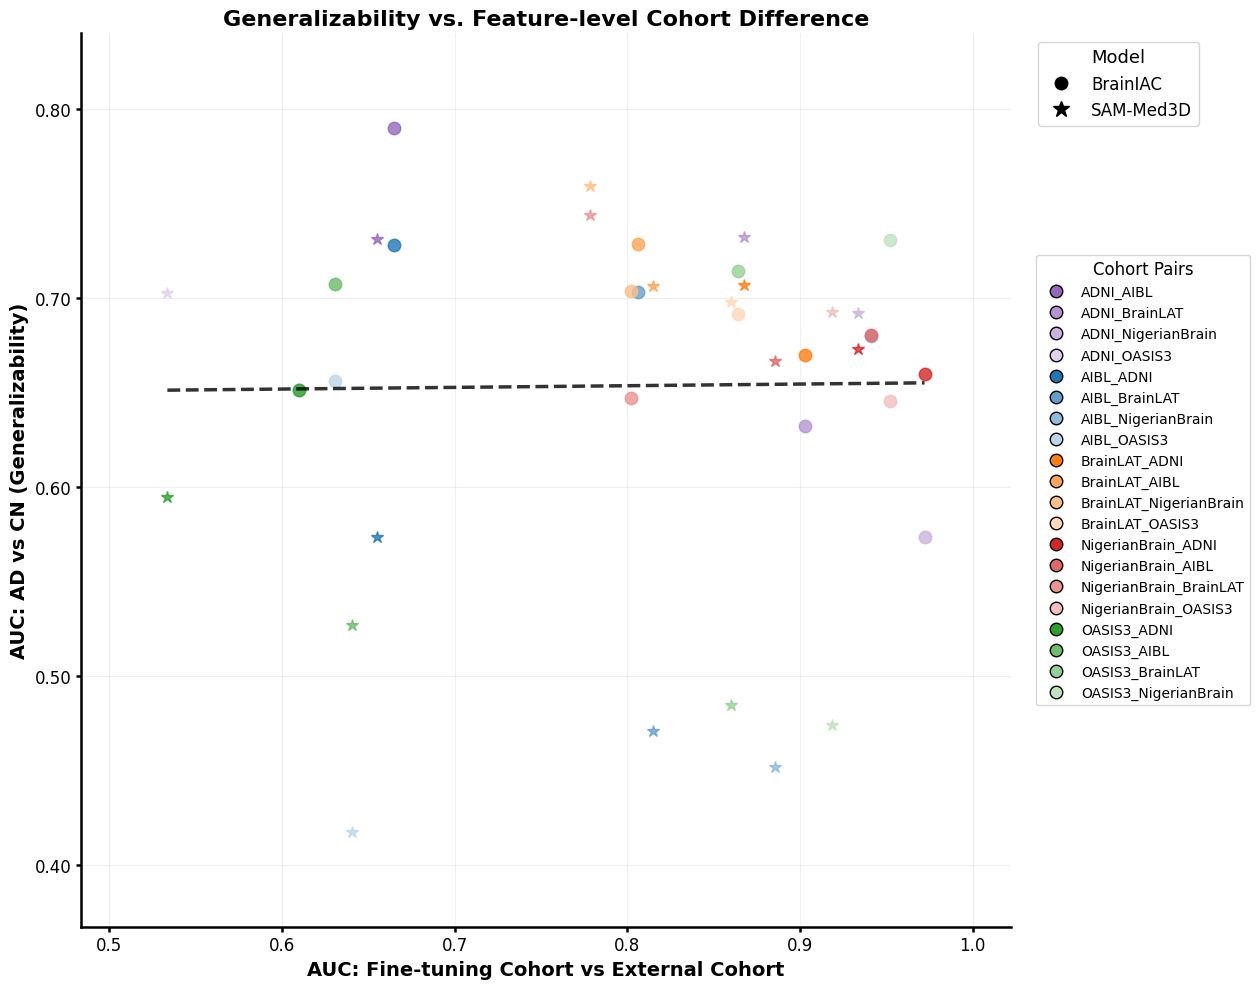

In [22]:
# -------------------------------
# Model markers
# -------------------------------
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*'}

# -------------------------------
# Base colors per fine-tuning cohort
# -------------------------------
base_colors = {
    "AIBL": "#1f77b4",        # blue
    "BrainLAT": "#ff7f0e",    # orange
    "OASIS3": "#2ca02c",       # green
    "NigerianBrain": "#d62728",  # red
    "ADNI": "#9467bd"         # purple
}

# -------------------------------
# Generate 4 shades per fine-tuning cohort
# -------------------------------
def lighten_color(color, amount=0.5):
    c = np.array(mcolors.to_rgb(color))
    white = np.array([1,1,1])
    return tuple(c + (white - c) * amount)

shades_per_cohort = {}
for cohort, base in base_colors.items():
    shades = [base]  # original
    for amt in [0.3, 0.5, 0.7]:  # lighter shades
        shades.append(mcolors.to_hex(lighten_color(base, amt)))
    shades_per_cohort[cohort] = shades

# -------------------------------
# Assign a color per fine-tuning → testing cohort pair
# -------------------------------
pair_color_map = {}
# Determine all unique testing cohorts per fine-tuning
ft_to_tests = {}
for name in exp_names:
    pair = name.split('-')[0]
    ft = pair.split('_')[0]
    test = pair.split('_')[1]
    if ft not in ft_to_tests:
        ft_to_tests[ft] = []
    if test not in ft_to_tests[ft]:
        ft_to_tests[ft].append(test)

# Map 4 shades to 4 testing cohorts
for ft, tests in ft_to_tests.items():
    for i, test in enumerate(sorted(tests)):
        pair = f"{ft}_{test}"
        pair_color_map[pair] = shades_per_cohort[ft][i]

# -------------------------------
# Prepare plot data
# -------------------------------
plot_data = []
for i, name in enumerate(exp_names):
    pair = name.split('-')[0]
    model = '-'.join(name.split('-')[1:])
    color = pair_color_map[pair]
    marker = marker_map.get(model)
    plot_data.append((pair, mean_cohort_acc[i], mean_adcn_acc[i],
                      std_cohort_acc[i], std_adcn_acc[i], color, marker))

plot_data.sort(key=lambda x: x[0])

# -------------------------------
# Create figure
# -------------------------------
plt.figure(figsize=(15, 10))
ax = plt.gca()

# Without Error bars
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.errorbar(x, y, fmt='none', color=color,
                capsize=4, capthick=1.5, elinewidth=1.5, alpha=0.5)

# Scatter points
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.plot(x, y, marker=marker, color=color, markersize=9, alpha=0.8,
            linestyle='none')

# # Plot error bars
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
#                  capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# # Plot scatter points
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
#              linestyle='none', label=name)

# Linear regression
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression().fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
        label='_nolegend_')

# Labels
ax.set_xlabel('AUC: Fine-tuning Cohort vs External Cohort', fontsize=14, fontweight='bold')
ax.set_ylabel('AUC: AD vs CN (Generalizability)', fontsize=14, fontweight='bold')
ax.set_title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.8)
ax.spines['left'].set_linewidth(1.8)
ax.tick_params(width=1.8, labelsize=12)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
ax.grid(True, alpha=0.2, linestyle='-')

# Axis limits
ax.set_xlim(min(mean_cohort_acc)-0.05, max(mean_cohort_acc)+0.05)
ax.set_ylim(min(mean_adcn_acc)-0.05, max(mean_adcn_acc)+0.05)

# -------------------------------
# Marker legend (model type)
# -------------------------------
marker_handles = [
    Line2D([0],[0], marker='o', color='black', linestyle='none', markersize=9, label='BrainIAC'),
    Line2D([0],[0], marker='*', color='black', linestyle='none', markersize=12, label='SAM-Med3D')
]
legend1 = ax.legend(handles=marker_handles, title='Model', loc='upper left',
                    bbox_to_anchor=(1.02, 1), fontsize=12, title_fontsize=13)
ax.add_artist(legend1)

# -------------------------------
# Legend for cohort pairs (20 lines)
# -------------------------------
legend_handles = []
seen_pairs = set()
for pair, x, y, xerr, yerr, color, marker in plot_data:
    if pair not in seen_pairs:
        handle = Line2D([0], [0], marker='o', color='black',
                        markerfacecolor=color, linestyle='none', markersize=9, label=pair)
        legend_handles.append(handle)
        seen_pairs.add(pair)

legend2 = ax.legend(handles=legend_handles, title='Cohort Pairs',
                    loc='center left', bbox_to_anchor=(1.02, 0.5),
                    fontsize=10, title_fontsize=12)

# Tight layout
plt.tight_layout(rect=[0,0,0.85,1])
plt.show()


# Balanced Accuracy

In [23]:
metric_col = 'balanced_accuracy'

In [24]:
cohort_summary = (
    df_cohort_all
    .groupby(["experiment", "model"])[metric_col]
    .agg(cohort_mean="mean", cohort_std="std")
    .reset_index()
)
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)


In [25]:
cohort_summary

,experiment,model,cohort_mean,cohort_std,cohort_pair
0,ADNI_AIBL,BrainIAC,0.618033,0.033523,"(ADNI, AIBL)"
1,ADNI_AIBL,SAM-Med3D,0.500000,0.000000,"(ADNI, AIBL)"
2,ADNI_BrainLAT,BrainIAC,0.717040,0.044259,"(ADNI, BrainLAT)"
3,ADNI_BrainLAT,SAM-Med3D,0.500000,0.000000,"(ADNI, BrainLAT)"
4,ADNI_NigerianBrain,BrainIAC,0.923625,0.035664,"(ADNI, NigerianBrain)"
5,ADNI_NigerianBrain,SAM-Med3D,0.781011,0.079045,"(ADNI, NigerianBrain)"
6,ADNI_OASIS3,BrainIAC,0.512870,0.013263,"(ADNI, OASIS3)"
7,ADNI_OASIS3,SAM-Med3D,0.500000,0.000000,"(ADNI, OASIS3)"
8,AIBL_BrainLAT,BrainIAC,0.692070,0.025298,"(AIBL, BrainLAT)"
9,AIBL_BrainLAT,SAM-Med3D,0.500000,0.000000,"(AIBL, BrainLAT)"


In [26]:
disease_summary = (
    df_disease_all
    .groupby(["train", "test", "model"])[metric_col]
    .agg(disease_mean="mean", disease_std="std")
    .reset_index()
)

disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)
disease_summary

,train,test,model,disease_mean,disease_std,cohort_pair
0,ADNI,AIBL,BrainIAC,0.707825,0.026730,"(ADNI, AIBL)"
1,ADNI,AIBL,SAM-Med3D,0.682319,0.011638,"(ADNI, AIBL)"
2,ADNI,BrainLAT,BrainIAC,0.564367,0.026061,"(ADNI, BrainLAT)"
3,ADNI,BrainLAT,SAM-Med3D,0.582564,0.018819,"(ADNI, BrainLAT)"
4,ADNI,NigerianBrain,BrainIAC,0.502295,0.045077,"(ADNI, NigerianBrain)"
5,ADNI,NigerianBrain,SAM-Med3D,0.602697,0.031752,"(ADNI, NigerianBrain)"
6,ADNI,OASIS3,BrainIAC,0.607345,0.011627,"(ADNI, OASIS3)"
7,ADNI,OASIS3,SAM-Med3D,0.634486,0.021507,"(ADNI, OASIS3)"
8,AIBL,ADNI,BrainIAC,0.598192,0.030670,"(ADNI, AIBL)"
9,AIBL,ADNI,SAM-Med3D,0.500125,0.000558,"(ADNI, AIBL)"


In [27]:
def add_cohort_pair(df):
    df = df.copy()
    df["cohort_pair"] = (
        df["experiment"]
        .str.split("_")
        .apply(lambda x: "_".join(sorted(x)))
    )
    return df

In [28]:
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)
disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)

In [29]:
combined_df = (
    disease_summary
    .merge(
        cohort_summary[["cohort_pair", "model", "cohort_mean", "cohort_std"]],
        on=["cohort_pair", "model"],
        how="inner"
    )
)

In [30]:
combined_df["cohort_pair"] = combined_df["cohort_pair"].apply(lambda x: "_".join(x))

In [31]:
combined_df

,train,test,model,disease_mean,disease_std,cohort_pair,cohort_mean,cohort_std
0,ADNI,AIBL,BrainIAC,0.707825,0.026730,ADNI_AIBL,0.618033,0.033523
1,ADNI,AIBL,SAM-Med3D,0.682319,0.011638,ADNI_AIBL,0.500000,0.000000
2,ADNI,BrainLAT,BrainIAC,0.564367,0.026061,ADNI_BrainLAT,0.717040,0.044259
3,ADNI,BrainLAT,SAM-Med3D,0.582564,0.018819,ADNI_BrainLAT,0.500000,0.000000
4,ADNI,NigerianBrain,BrainIAC,0.502295,0.045077,ADNI_NigerianBrain,0.923625,0.035664
5,ADNI,NigerianBrain,SAM-Med3D,0.602697,0.031752,ADNI_NigerianBrain,0.781011,0.079045
6,ADNI,OASIS3,BrainIAC,0.607345,0.011627,ADNI_OASIS3,0.512870,0.013263
7,ADNI,OASIS3,SAM-Med3D,0.634486,0.021507,ADNI_OASIS3,0.500000,0.000000
8,AIBL,ADNI,BrainIAC,0.598192,0.030670,ADNI_AIBL,0.618033,0.033523
9,AIBL,ADNI,SAM-Med3D,0.500125,0.000558,ADNI_AIBL,0.500000,0.000000


In [32]:
combined_df['experiment'] = combined_df['train'] + '_' + combined_df['test'] + '-' + combined_df['model']

In [33]:
rho, p_value = stats.spearmanr(combined_df['cohort_mean'], combined_df['disease_mean'])
rho, p_value

(0.1149484079830703, 0.4800072063193386)

In [34]:
stats_r = importr('stats')
# convert to R dataframe
with localconverter(pandas2ri.converter):
    r_df = pandas2ri.py2rpy(combined_df)

In [35]:
# ----- ANOVA: disease_mean ~ cohort_mean -----
anova1 = stats_r.aov(r('disease_mean ~ cohort_mean'), data=r_df)
print(r['summary'](anova1))

R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  


            Df  Sum Sq  Mean Sq F value Pr(>F)
cohort_mean  1 0.00034 0.000342   0.102  0.752
Residuals   38 0.12778 0.003363               



In [36]:
# ----- ANOVA: disease_mean ~ cohort_mean + model -----
anova2 = stats_r.aov(r('disease_mean ~ cohort_mean + model'), data=r_df)
print(r['summary'](anova2))

            Df  Sum Sq  Mean Sq F value Pr(>F)
cohort_mean  1 0.00034 0.000342   0.099  0.755
model        1 0.00034 0.000335   0.097  0.757
Residuals   37 0.12744 0.003444               



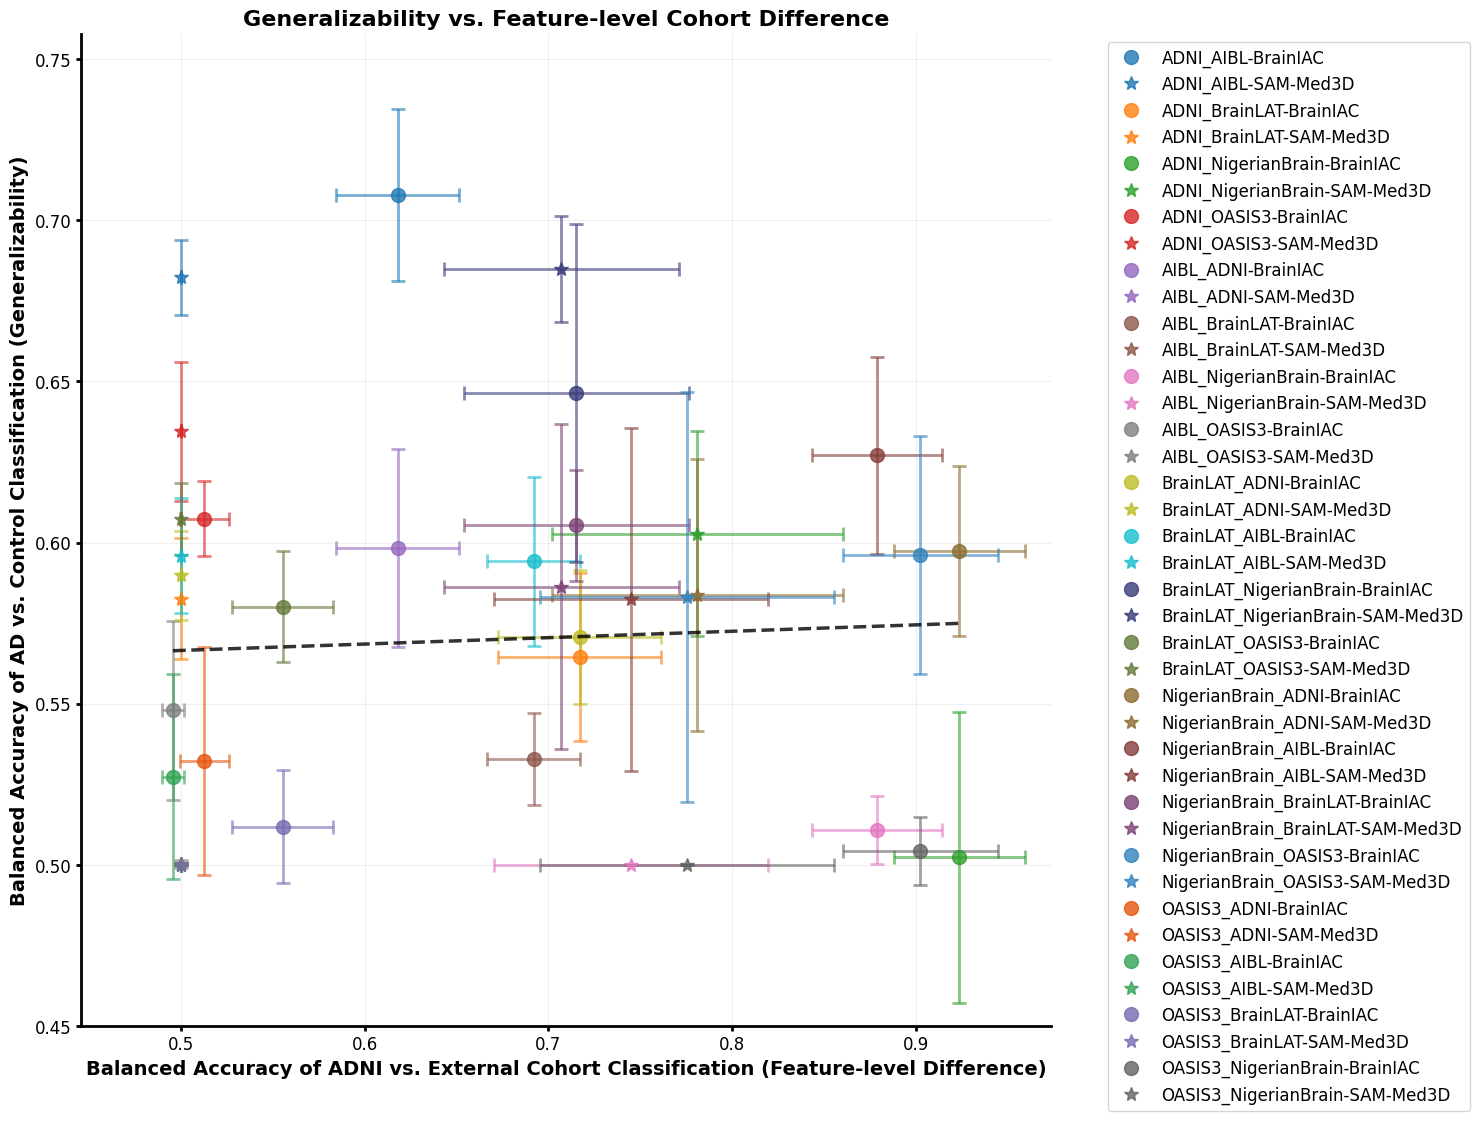

Spearman's ρ (rho): 0.115, p-value: 0.4800
Pearson's r: 0.052, p-value: 0.7517


In [38]:
# Example exp_names (for context)

exp_names = combined_df['experiment'].tolist()

# Define colors for each dataset prefix
dataset_names = sorted(set([name.split('-')[0] for name in exp_names]))
color_map = dict(zip(dataset_names,  [
    "#1f77b4",  # Blue
    "#ff7f0e",  # Orange
    "#2ca02c",  # Green
    "#d62728",  # Red
    "#9467bd",  # Purple
    "#8c564b",  # Brown
    "#e377c2",  # Pink
    "#7f7f7f",  # Gray
    "#bcbd22",  # Olive
    "#17becf",  # Teal
    "#393b79",  # Dark Blue
    "#637939",  # Dark Green
    "#8c6d31",  # Dark Brown
    "#843c39",  # Dark Red
    "#7b4173",  # Violet
    "#3182bd",  # Light Blue
    "#e6550d",  # Deep Orange
    "#31a354",  # Bright Green
    "#756bb1",  # Medium Purple
    "#636363"   # Dark Gray
]))

# Assign markers based on suffix
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*'}

mean_cohort_acc = combined_df['cohort_mean'].values
mean_adcn_acc = combined_df['disease_mean'].values
std_cohort_acc = combined_df['cohort_std'].values
std_adcn_acc = combined_df['disease_std'].values
# Prepare plot data with color and marker
plot_data = []
for i, name in enumerate(exp_names):
    dataset_prefix = name.split('-')[0]
    experiment_suffix = '-'.join(name.split('-')[1:])
    color = color_map[dataset_prefix]
    marker = marker_map.get(experiment_suffix, 'o')  # default to circle if unknown
    plot_data.append((name, mean_cohort_acc[i], mean_adcn_acc[i], 
                     std_cohort_acc[i], std_adcn_acc[i], color, marker))

# Sort alphabetically for legend
plot_data.sort(key=lambda x: x[0])

# Create figure
plt.figure(figsize=(15, 12))

# Plot error bars
for name, x, y, xerr, yerr, color, marker in plot_data:
    plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
                 capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# Plot scatter points
for name, x, y, xerr, yerr, color, marker in plot_data:
    plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
             linestyle='none', label=name)

# Linear regression trend line
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression()
lr_model.fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
plt.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
         label='_nolegend_')  # prevents trendline from appearing in legend

# Labels and title
plt.xlabel('Balanced Accuracy of ADNI vs. External Cohort Classification (Feature-level Difference)', fontsize=14, fontweight='bold')
plt.ylabel('Balanced Accuracy of AD vs. Control Classification (Generalizability)', fontsize=14, fontweight='bold')
plt.title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes formatting
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.tick_params(width=2, labelsize=12)

ax = plt.gca()
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
plt.grid(True, alpha=0.2, linestyle='-')

# Axis limits with padding
plt.xlim(min(mean_cohort_acc) - 0.05, max(mean_cohort_acc) + 0.05)
plt.ylim(min(mean_adcn_acc) - 0.05, max(mean_adcn_acc) + 0.05)

# Legend below plot, alphabetical order
handles, labels = ax.get_legend_handles_labels()
sorted_handles_labels = sorted(zip(labels, handles), key=lambda x: x[0])
labels_sorted, handles_sorted = zip(*sorted_handles_labels)
plt.legend(handles_sorted, labels_sorted, bbox_to_anchor=(1.05, 1), loc='upper left',
           fontsize=12)

plt.tight_layout()
plt.show()

# Spearman correlation
rho, p_value = stats.spearmanr(mean_cohort_acc, mean_adcn_acc)
print(f"Spearman's ρ (rho): {rho:.3f}, p-value: {p_value:.4f}")

# Pearson correlation
pearson_r, pearson_p = stats.pearsonr(mean_cohort_acc, mean_adcn_acc)
print(f"Pearson's r: {pearson_r:.3f}, p-value: {pearson_p:.4f}")


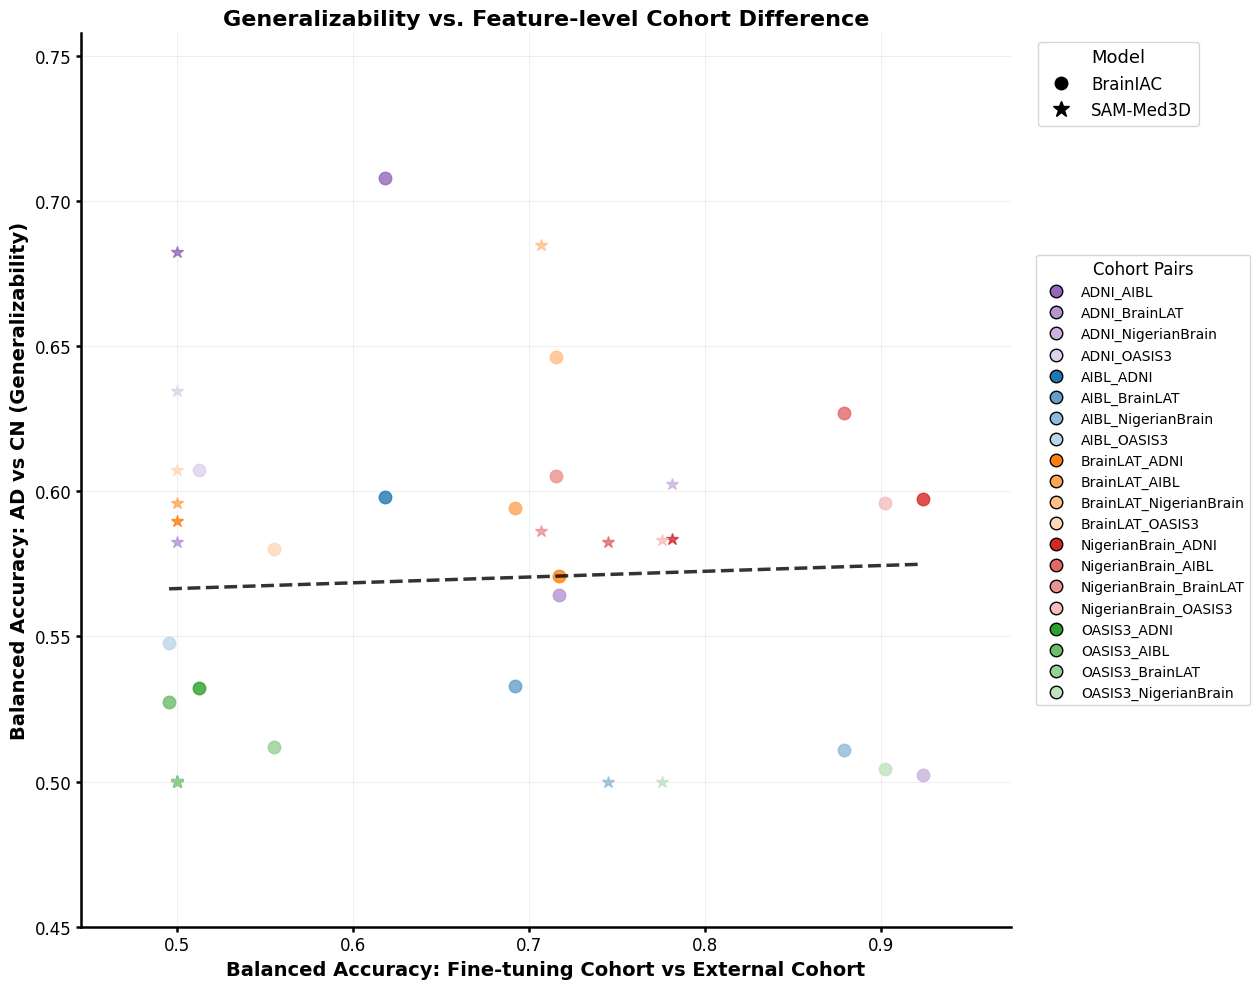

In [39]:
# -------------------------------
# Model markers
# -------------------------------
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*'}

# -------------------------------
# Base colors per fine-tuning cohort
# -------------------------------
base_colors = {
    "AIBL": "#1f77b4",        # blue
    "BrainLAT": "#ff7f0e",    # orange
    "OASIS3": "#2ca02c",       # green
    "NigerianBrain": "#d62728",  # red
    "ADNI": "#9467bd"         # purple
}

# -------------------------------
# Generate 4 shades per fine-tuning cohort
# -------------------------------
def lighten_color(color, amount=0.5):
    c = np.array(mcolors.to_rgb(color))
    white = np.array([1,1,1])
    return tuple(c + (white - c) * amount)

shades_per_cohort = {}
for cohort, base in base_colors.items():
    shades = [base]  # original
    for amt in [0.3, 0.5, 0.7]:  # lighter shades
        shades.append(mcolors.to_hex(lighten_color(base, amt)))
    shades_per_cohort[cohort] = shades

# -------------------------------
# Assign a color per fine-tuning → testing cohort pair
# -------------------------------
pair_color_map = {}
# Determine all unique testing cohorts per fine-tuning
ft_to_tests = {}
for name in exp_names:
    pair = name.split('-')[0]
    ft = pair.split('_')[0]
    test = pair.split('_')[1]
    if ft not in ft_to_tests:
        ft_to_tests[ft] = []
    if test not in ft_to_tests[ft]:
        ft_to_tests[ft].append(test)

# Map 4 shades to 4 testing cohorts
for ft, tests in ft_to_tests.items():
    for i, test in enumerate(sorted(tests)):
        pair = f"{ft}_{test}"
        pair_color_map[pair] = shades_per_cohort[ft][i]

# -------------------------------
# Prepare plot data
# -------------------------------
plot_data = []
for i, name in enumerate(exp_names):
    pair = name.split('-')[0]
    model = '-'.join(name.split('-')[1:])
    color = pair_color_map[pair]
    marker = marker_map.get(model)
    plot_data.append((pair, mean_cohort_acc[i], mean_adcn_acc[i],
                      std_cohort_acc[i], std_adcn_acc[i], color, marker))

plot_data.sort(key=lambda x: x[0])

# -------------------------------
# Create figure
# -------------------------------
plt.figure(figsize=(15, 10))
ax = plt.gca()

# Without Error bars
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.errorbar(x, y, fmt='none', color=color,
                capsize=4, capthick=1.5, elinewidth=1.5, alpha=0.5)

# Scatter points
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.plot(x, y, marker=marker, color=color, markersize=9, alpha=0.8,
            linestyle='none')

# # Plot error bars
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
#                  capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# # Plot scatter points
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
#              linestyle='none', label=name)

# Linear regression
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression().fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
        label='_nolegend_')

# Labels
ax.set_xlabel('Balanced Accuracy: Fine-tuning Cohort vs External Cohort', fontsize=14, fontweight='bold')
ax.set_ylabel('Balanced Accuracy: AD vs CN (Generalizability)', fontsize=14, fontweight='bold')
ax.set_title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.8)
ax.spines['left'].set_linewidth(1.8)
ax.tick_params(width=1.8, labelsize=12)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
ax.grid(True, alpha=0.2, linestyle='-')

# Axis limits
ax.set_xlim(min(mean_cohort_acc)-0.05, max(mean_cohort_acc)+0.05)
ax.set_ylim(min(mean_adcn_acc)-0.05, max(mean_adcn_acc)+0.05)

# -------------------------------
# Marker legend (model type)
# -------------------------------
marker_handles = [
    Line2D([0],[0], marker='o', color='black', linestyle='none', markersize=9, label='BrainIAC'),
    Line2D([0],[0], marker='*', color='black', linestyle='none', markersize=12, label='SAM-Med3D')
]
legend1 = ax.legend(handles=marker_handles, title='Model', loc='upper left',
                    bbox_to_anchor=(1.02, 1), fontsize=12, title_fontsize=13)
ax.add_artist(legend1)

# -------------------------------
# Legend for cohort pairs (20 lines)
# -------------------------------
legend_handles = []
seen_pairs = set()
for pair, x, y, xerr, yerr, color, marker in plot_data:
    if pair not in seen_pairs:
        handle = Line2D([0], [0], marker='o', color='black',
                        markerfacecolor=color, linestyle='none', markersize=9, label=pair)
        legend_handles.append(handle)
        seen_pairs.add(pair)

legend2 = ax.legend(handles=legend_handles, title='Cohort Pairs',
                    loc='center left', bbox_to_anchor=(1.02, 0.5),
                    fontsize=10, title_fontsize=12)

# Tight layout
plt.tight_layout(rect=[0,0,0.85,1])
plt.show()


# F1 Score

In [41]:
metric_col = 'f1_score'

In [42]:
cohort_summary = (
    df_cohort_all
    .groupby(["experiment", "model"])[metric_col]
    .agg(cohort_mean="mean", cohort_std="std")
    .reset_index()
)
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)


In [43]:
cohort_summary

,experiment,model,cohort_mean,cohort_std,cohort_pair
0,ADNI_AIBL,BrainIAC,0.809094,0.012759,"(ADNI, AIBL)"
1,ADNI_AIBL,SAM-Med3D,0.778267,0.000000,"(ADNI, AIBL)"
2,ADNI_BrainLAT,BrainIAC,0.920658,0.009684,"(ADNI, BrainLAT)"
3,ADNI_BrainLAT,SAM-Med3D,0.870279,0.000000,"(ADNI, BrainLAT)"
4,ADNI_NigerianBrain,BrainIAC,0.980723,0.013176,"(ADNI, NigerianBrain)"
5,ADNI_NigerianBrain,SAM-Med3D,0.987502,0.003222,"(ADNI, NigerianBrain)"
6,ADNI_OASIS3,BrainIAC,0.072259,0.061835,"(ADNI, OASIS3)"
7,ADNI_OASIS3,SAM-Med3D,0.000000,0.000000,"(ADNI, OASIS3)"
8,AIBL_BrainLAT,BrainIAC,0.831560,0.015499,"(AIBL, BrainLAT)"
9,AIBL_BrainLAT,SAM-Med3D,0.792651,0.000000,"(AIBL, BrainLAT)"


In [44]:
disease_summary = (
    df_disease_all
    .groupby(["train", "test", "model"])[metric_col]
    .agg(disease_mean="mean", disease_std="std")
    .reset_index()
)

disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)
disease_summary

,train,test,model,disease_mean,disease_std,cohort_pair
0,ADNI,AIBL,BrainIAC,0.423523,0.048160,"(ADNI, AIBL)"
1,ADNI,AIBL,SAM-Med3D,0.425561,0.020191,"(ADNI, AIBL)"
2,ADNI,BrainLAT,BrainIAC,0.429708,0.102700,"(ADNI, BrainLAT)"
3,ADNI,BrainLAT,SAM-Med3D,0.395189,0.061024,"(ADNI, BrainLAT)"
4,ADNI,NigerianBrain,BrainIAC,0.291723,0.118539,"(ADNI, NigerianBrain)"
5,ADNI,NigerianBrain,SAM-Med3D,0.471404,0.071418,"(ADNI, NigerianBrain)"
6,ADNI,OASIS3,BrainIAC,0.206743,0.016683,"(ADNI, OASIS3)"
7,ADNI,OASIS3,SAM-Med3D,0.240094,0.012460,"(ADNI, OASIS3)"
8,AIBL,ADNI,BrainIAC,0.402339,0.105568,"(ADNI, AIBL)"
9,AIBL,ADNI,SAM-Med3D,0.000496,0.002219,"(ADNI, AIBL)"


In [45]:
def add_cohort_pair(df):
    df = df.copy()
    df["cohort_pair"] = (
        df["experiment"]
        .str.split("_")
        .apply(lambda x: "_".join(sorted(x)))
    )
    return df

In [46]:
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)
disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)

In [47]:
combined_df = (
    disease_summary
    .merge(
        cohort_summary[["cohort_pair", "model", "cohort_mean", "cohort_std"]],
        on=["cohort_pair", "model"],
        how="inner"
    )
)

In [48]:
combined_df["cohort_pair"] = combined_df["cohort_pair"].apply(lambda x: "_".join(x))

In [49]:
combined_df

,train,test,model,disease_mean,disease_std,cohort_pair,cohort_mean,cohort_std
0,ADNI,AIBL,BrainIAC,0.423523,0.048160,ADNI_AIBL,0.809094,0.012759
1,ADNI,AIBL,SAM-Med3D,0.425561,0.020191,ADNI_AIBL,0.778267,0.000000
2,ADNI,BrainLAT,BrainIAC,0.429708,0.102700,ADNI_BrainLAT,0.920658,0.009684
3,ADNI,BrainLAT,SAM-Med3D,0.395189,0.061024,ADNI_BrainLAT,0.870279,0.000000
4,ADNI,NigerianBrain,BrainIAC,0.291723,0.118539,ADNI_NigerianBrain,0.980723,0.013176
5,ADNI,NigerianBrain,SAM-Med3D,0.471404,0.071418,ADNI_NigerianBrain,0.987502,0.003222
6,ADNI,OASIS3,BrainIAC,0.206743,0.016683,ADNI_OASIS3,0.072259,0.061835
7,ADNI,OASIS3,SAM-Med3D,0.240094,0.012460,ADNI_OASIS3,0.000000,0.000000
8,AIBL,ADNI,BrainIAC,0.402339,0.105568,ADNI_AIBL,0.809094,0.012759
9,AIBL,ADNI,SAM-Med3D,0.000496,0.002219,ADNI_AIBL,0.778267,0.000000


In [50]:
combined_df['experiment'] = combined_df['train'] + '_' + combined_df['test'] + '-' + combined_df['model']

In [51]:
rho, p_value = stats.spearmanr(combined_df['cohort_mean'], combined_df['disease_mean'])
rho, p_value

(0.21997460853056752, 0.17259926662179176)

In [52]:
stats_r = importr('stats')
# convert to R dataframe
with localconverter(pandas2ri.converter):
    r_df = pandas2ri.py2rpy(combined_df)

In [53]:
# ----- ANOVA: disease_mean ~ cohort_mean -----
anova1 = stats_r.aov(r('disease_mean ~ cohort_mean'), data=r_df)
print(r['summary'](anova1))

R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  


            Df Sum Sq Mean Sq F value Pr(>F)  
cohort_mean  1 0.2033 0.20326   5.106 0.0297 *
Residuals   38 1.5127 0.03981                 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



In [54]:
# ----- ANOVA: disease_mean ~ cohort_mean + model -----
anova2 = stats_r.aov(r('disease_mean ~ cohort_mean + model'), data=r_df)
print(r['summary'](anova2))

            Df Sum Sq Mean Sq F value Pr(>F)  
cohort_mean  1 0.2033 0.20326   5.148 0.0292 *
model        1 0.0518 0.05178   1.311 0.2595  
Residuals   37 1.4609 0.03949                 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



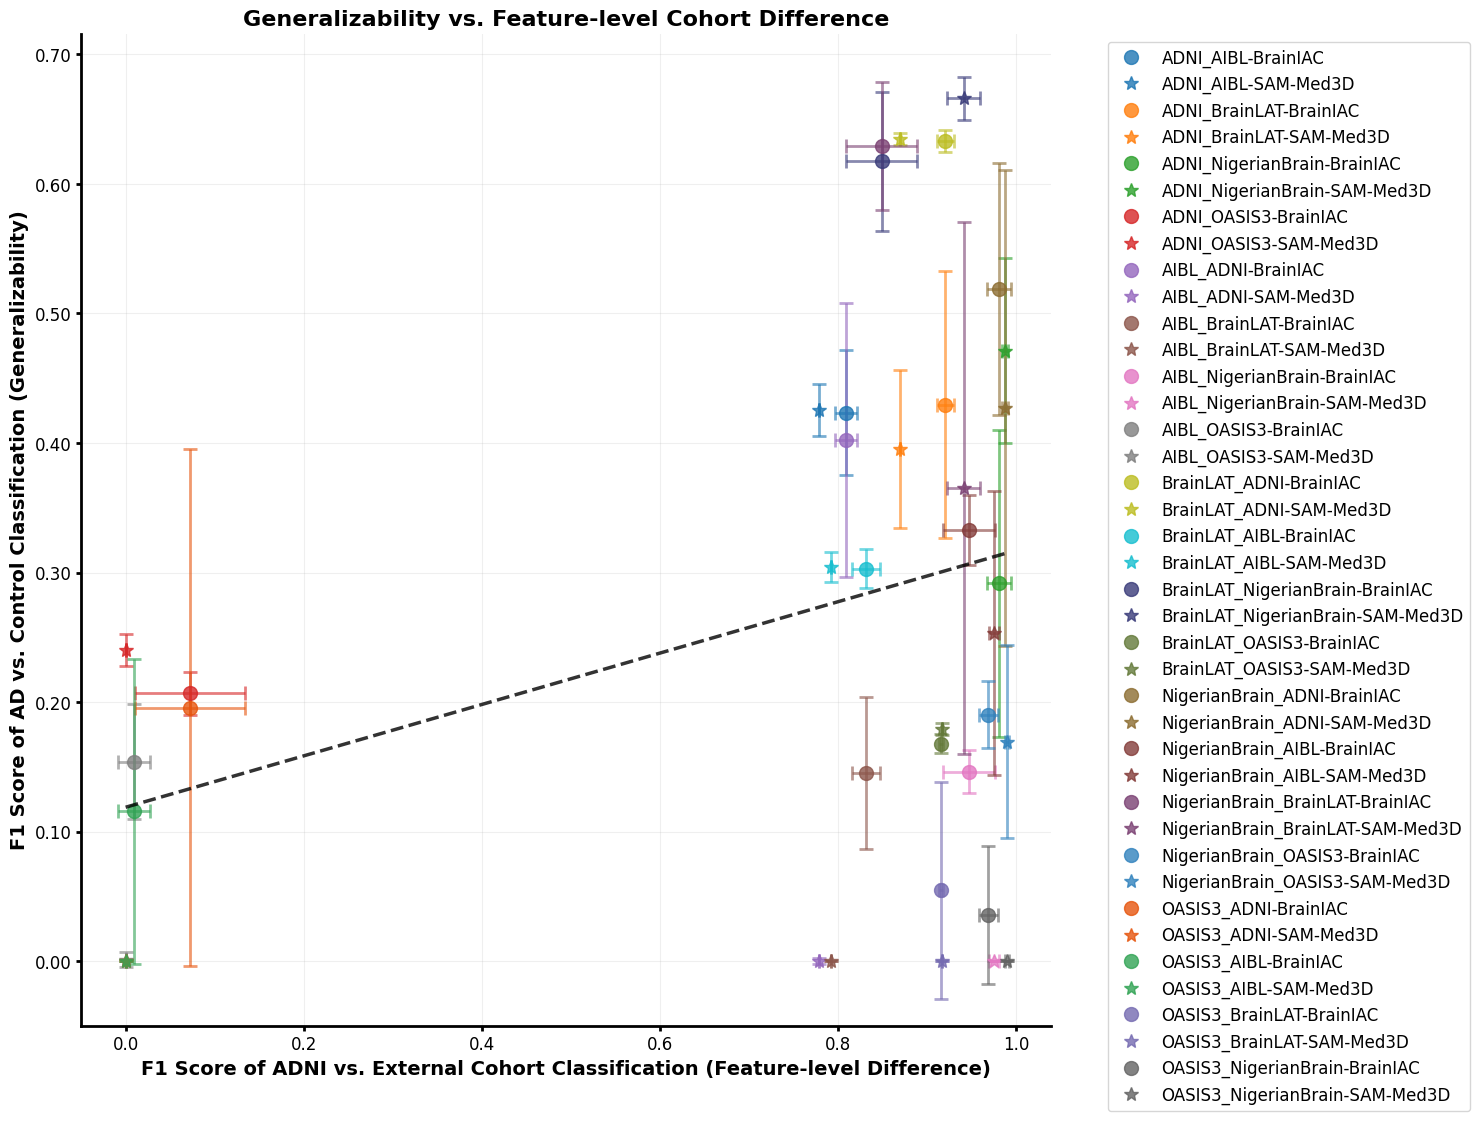

Spearman's ρ (rho): 0.220, p-value: 0.1726
Pearson's r: 0.344, p-value: 0.0297


In [55]:
# Example exp_names (for context)

exp_names = combined_df['experiment'].tolist()

# Define colors for each dataset prefix
dataset_names = sorted(set([name.split('-')[0] for name in exp_names]))
color_map = dict(zip(dataset_names,  [
    "#1f77b4",  # Blue
    "#ff7f0e",  # Orange
    "#2ca02c",  # Green
    "#d62728",  # Red
    "#9467bd",  # Purple
    "#8c564b",  # Brown
    "#e377c2",  # Pink
    "#7f7f7f",  # Gray
    "#bcbd22",  # Olive
    "#17becf",  # Teal
    "#393b79",  # Dark Blue
    "#637939",  # Dark Green
    "#8c6d31",  # Dark Brown
    "#843c39",  # Dark Red
    "#7b4173",  # Violet
    "#3182bd",  # Light Blue
    "#e6550d",  # Deep Orange
    "#31a354",  # Bright Green
    "#756bb1",  # Medium Purple
    "#636363"   # Dark Gray
]))

# Assign markers based on suffix
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*'}

mean_cohort_acc = combined_df['cohort_mean'].values
mean_adcn_acc = combined_df['disease_mean'].values
std_cohort_acc = combined_df['cohort_std'].values
std_adcn_acc = combined_df['disease_std'].values
# Prepare plot data with color and marker
plot_data = []
for i, name in enumerate(exp_names):
    dataset_prefix = name.split('-')[0]
    experiment_suffix = '-'.join(name.split('-')[1:])
    color = color_map[dataset_prefix]
    marker = marker_map.get(experiment_suffix, 'o')  # default to circle if unknown
    plot_data.append((name, mean_cohort_acc[i], mean_adcn_acc[i], 
                     std_cohort_acc[i], std_adcn_acc[i], color, marker))

# Sort alphabetically for legend
plot_data.sort(key=lambda x: x[0])

# Create figure
plt.figure(figsize=(15, 12))

# Plot error bars
for name, x, y, xerr, yerr, color, marker in plot_data:
    plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
                 capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# Plot scatter points
for name, x, y, xerr, yerr, color, marker in plot_data:
    plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
             linestyle='none', label=name)

# Linear regression trend line
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression()
lr_model.fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
plt.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
         label='_nolegend_')  # prevents trendline from appearing in legend

# Labels and title
plt.xlabel('F1 Score of ADNI vs. External Cohort Classification (Feature-level Difference)', fontsize=14, fontweight='bold')
plt.ylabel('F1 Score of AD vs. Control Classification (Generalizability)', fontsize=14, fontweight='bold')
plt.title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes formatting
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.tick_params(width=2, labelsize=12)

ax = plt.gca()
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
plt.grid(True, alpha=0.2, linestyle='-')

# Axis limits with padding
plt.xlim(min(mean_cohort_acc) - 0.05, max(mean_cohort_acc) + 0.05)
plt.ylim(min(mean_adcn_acc) - 0.05, max(mean_adcn_acc) + 0.05)

# Legend below plot, alphabetical order
handles, labels = ax.get_legend_handles_labels()
sorted_handles_labels = sorted(zip(labels, handles), key=lambda x: x[0])
labels_sorted, handles_sorted = zip(*sorted_handles_labels)
plt.legend(handles_sorted, labels_sorted, bbox_to_anchor=(1.05, 1), loc='upper left',
           fontsize=12)

plt.tight_layout()
plt.show()

# Spearman correlation
rho, p_value = stats.spearmanr(mean_cohort_acc, mean_adcn_acc)
print(f"Spearman's ρ (rho): {rho:.3f}, p-value: {p_value:.4f}")

# Pearson correlation
pearson_r, pearson_p = stats.pearsonr(mean_cohort_acc, mean_adcn_acc)
print(f"Pearson's r: {pearson_r:.3f}, p-value: {pearson_p:.4f}")


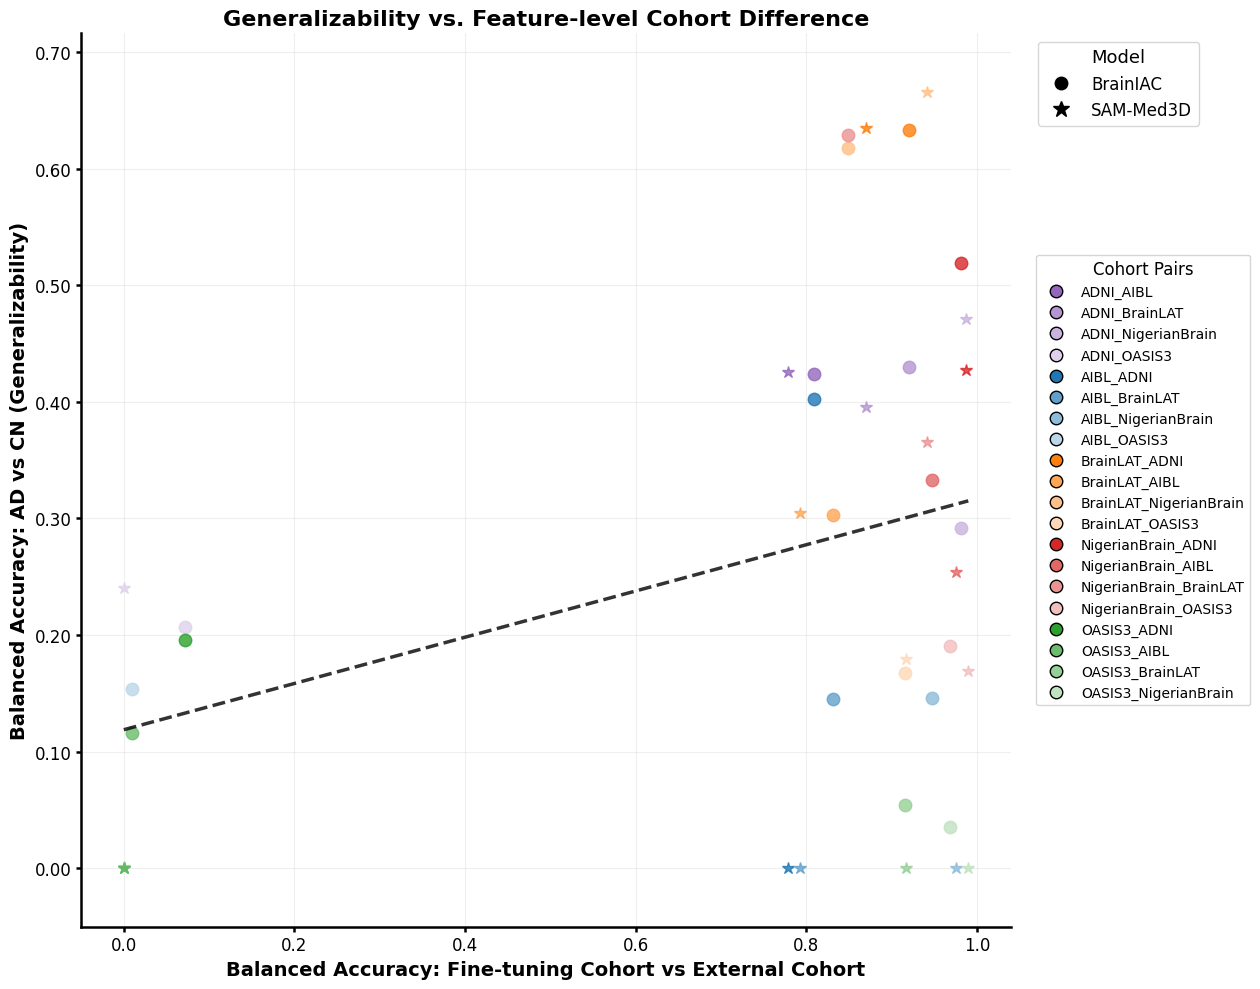

In [57]:
# -------------------------------
# Model markers
# -------------------------------
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*'}

# -------------------------------
# Base colors per fine-tuning cohort
# -------------------------------
base_colors = {
    "AIBL": "#1f77b4",        # blue
    "BrainLAT": "#ff7f0e",    # orange
    "OASIS3": "#2ca02c",       # green
    "NigerianBrain": "#d62728",  # red
    "ADNI": "#9467bd"         # purple
}

# -------------------------------
# Generate 4 shades per fine-tuning cohort
# -------------------------------
def lighten_color(color, amount=0.5):
    c = np.array(mcolors.to_rgb(color))
    white = np.array([1,1,1])
    return tuple(c + (white - c) * amount)

shades_per_cohort = {}
for cohort, base in base_colors.items():
    shades = [base]  # original
    for amt in [0.3, 0.5, 0.7]:  # lighter shades
        shades.append(mcolors.to_hex(lighten_color(base, amt)))
    shades_per_cohort[cohort] = shades

# -------------------------------
# Assign a color per fine-tuning → testing cohort pair
# -------------------------------
pair_color_map = {}
# Determine all unique testing cohorts per fine-tuning
ft_to_tests = {}
for name in exp_names:
    pair = name.split('-')[0]
    ft = pair.split('_')[0]
    test = pair.split('_')[1]
    if ft not in ft_to_tests:
        ft_to_tests[ft] = []
    if test not in ft_to_tests[ft]:
        ft_to_tests[ft].append(test)

# Map 4 shades to 4 testing cohorts
for ft, tests in ft_to_tests.items():
    for i, test in enumerate(sorted(tests)):
        pair = f"{ft}_{test}"
        pair_color_map[pair] = shades_per_cohort[ft][i]

# -------------------------------
# Prepare plot data
# -------------------------------
plot_data = []
for i, name in enumerate(exp_names):
    pair = name.split('-')[0]
    model = '-'.join(name.split('-')[1:])
    color = pair_color_map[pair]
    marker = marker_map.get(model)
    plot_data.append((pair, mean_cohort_acc[i], mean_adcn_acc[i],
                      std_cohort_acc[i], std_adcn_acc[i], color, marker))

plot_data.sort(key=lambda x: x[0])

# -------------------------------
# Create figure
# -------------------------------
plt.figure(figsize=(15, 10))
ax = plt.gca()

# Without Error bars
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.errorbar(x, y, fmt='none', color=color,
                capsize=4, capthick=1.5, elinewidth=1.5, alpha=0.5)

# Scatter points
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.plot(x, y, marker=marker, color=color, markersize=9, alpha=0.8,
            linestyle='none')

# # Plot error bars
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
#                  capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# # Plot scatter points
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
#              linestyle='none', label=name)

# Linear regression
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression().fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
        label='_nolegend_')

# Labels
ax.set_xlabel('Balanced Accuracy: Fine-tuning Cohort vs External Cohort', fontsize=14, fontweight='bold')
ax.set_ylabel('Balanced Accuracy: AD vs CN (Generalizability)', fontsize=14, fontweight='bold')
ax.set_title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.8)
ax.spines['left'].set_linewidth(1.8)
ax.tick_params(width=1.8, labelsize=12)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
ax.grid(True, alpha=0.2, linestyle='-')

# Axis limits
ax.set_xlim(min(mean_cohort_acc)-0.05, max(mean_cohort_acc)+0.05)
ax.set_ylim(min(mean_adcn_acc)-0.05, max(mean_adcn_acc)+0.05)

# -------------------------------
# Marker legend (model type)
# -------------------------------
marker_handles = [
    Line2D([0],[0], marker='o', color='black', linestyle='none', markersize=9, label='BrainIAC'),
    Line2D([0],[0], marker='*', color='black', linestyle='none', markersize=12, label='SAM-Med3D')
]
legend1 = ax.legend(handles=marker_handles, title='Model', loc='upper left',
                    bbox_to_anchor=(1.02, 1), fontsize=12, title_fontsize=13)
ax.add_artist(legend1)

# -------------------------------
# Legend for cohort pairs (20 lines)
# -------------------------------
legend_handles = []
seen_pairs = set()
for pair, x, y, xerr, yerr, color, marker in plot_data:
    if pair not in seen_pairs:
        handle = Line2D([0], [0], marker='o', color='black',
                        markerfacecolor=color, linestyle='none', markersize=9, label=pair)
        legend_handles.append(handle)
        seen_pairs.add(pair)

legend2 = ax.legend(handles=legend_handles, title='Cohort Pairs',
                    loc='center left', bbox_to_anchor=(1.02, 0.5),
                    fontsize=10, title_fontsize=12)

# Tight layout
plt.tight_layout(rect=[0,0,0.85,1])
plt.show()
